# Contextual-Care Benchmark

Downstream evaluation of the simulators on the human-coded *Contextualizing Care* (4C) annotations that come with the VHA transcripts. Each red flag of a visit (e.g. uncontrolled diabetes) is injected into the patient's profile together with its coded contextual factor (e.g. the patient dislikes pricking their finger). A doctor model is briefed with the clinician-observable red flags only, interviews the simulated patient, and states for every flag the contextual cause and a care plan. A Gemini 3.1 Pro judge scores the answer against the coding:

- **cause correct** — the stated cause is the coded factor;
- **contextual error** — the plan does not address the coded factor;
- **factor elicited** — the patient voices the factor in the conversation.

The **real visit** reference gives the same doctor model the recorded encounter instead of an interview (`real_no_plan`: every turn overlapping a coded care-plan span is removed, since it would leak the physician's plan). A simulator that makes the interview easier than this reference makes the benchmark easier than reality.

Runs: `scripts/run_contextual_care_benchmark.py` with `contextual_care_vha` (30 cases) and `contextual_care_vha_ext` (62 cases), three seeds, doctors Gemini 3.1 Flash-Lite / Gemini 3.5 Flash / Claude Sonnet 5.5. `strong` is the doctor arm instructed to explore the circumstances behind every flag (≤20 turns); `weak` keeps a brief biomedical focus (≤8 turns).

In [1]:
import os

os.chdir("..")

In [2]:
import json
from pathlib import Path

import pandas as pd

from patient_simulator.misc import contextual_care as cc
from patient_simulator.misc.plotting import save_to_figures

pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 200)

RESULTS = [
    Path("results/contextual_care_vha/results.csv"),
    Path("results/contextual_care_vha_ext/results.csv"),
]
REFERENCE = "real_no_plan"
DOCTOR = "strong"
SIMULATOR_ARMS = [REFERENCE] + [
    f"{DOCTOR}:{s}" for s in ["PWP", "PatientSim", "AgentClinic"]
]

df = cc.load_results(RESULTS)
draws = cc.case_bootstrap(df, n_boot=2000, seed=0)
n_factors = df[df.has_factor][["case_id", "flag_idx"]].drop_duplicates().shape[0]
print(
    f"{df.case_id.nunique()} cases with coded factors, {n_factors} factors, seeds {sorted(df.run.unique())}"
)

87 cases with coded factors, 206 factors, seeds [np.int64(0), np.int64(1), np.int64(2)]


## Rates per doctor model

Pooled rate with 95% case-bootstrap interval; in parentheses the paired difference to the real visit (`*` = interval excludes 0).

In [3]:
for metric in ["contextual_error", "cause_correct", "factor_elicited"]:
    print(f"\n{metric}")
    print(cc.rate_table(draws, SIMULATOR_ARMS, metric).to_string())


contextual_error
                                        Gemini 3.1 Flash-Lite                           Gemini 3.5 Flash                          Claude Sonnet 5.5
real_no_plan                                0.45 [0.39, 0.52]                          0.34 [0.28, 0.40]                          0.15 [0.11, 0.20]
strong:PWP          0.33 [0.27, 0.39] (-0.13 [-0.19, -0.06]*)  0.23 [0.19, 0.28] (-0.11 [-0.17, -0.04]*)    0.15 [0.12, 0.18] (-0.00 [-0.05, 0.04])
strong:PatientSim   0.17 [0.12, 0.22] (-0.28 [-0.34, -0.22]*)  0.12 [0.08, 0.16] (-0.22 [-0.29, -0.15]*)  0.08 [0.05, 0.11] (-0.07 [-0.11, -0.04]*)
strong:AgentClinic  0.20 [0.15, 0.25] (-0.26 [-0.32, -0.19]*)  0.10 [0.07, 0.13] (-0.24 [-0.30, -0.18]*)  0.07 [0.05, 0.10] (-0.08 [-0.12, -0.04]*)

cause_correct
                                      Gemini 3.1 Flash-Lite                           Gemini 3.5 Flash                          Claude Sonnet 5.5
real_no_plan                              0.63 [0.57, 0.69]                      

## Distance to the real visit

$|\text{simulator} - \text{real}|$ per doctor model and averaged over models. `PWP - <baseline>` below zero means PWP is closer to the real visit.

In [4]:
for metric in ["contextual_error", "cause_correct"]:
    print(f"\n{metric}")
    print(cc.distance_to_real_table(draws, REFERENCE, metric, DOCTOR).to_string())


contextual_error
                            |PWP - real| |PatientSim - real| |AgentClinic - real|       PWP - PatientSim      PWP - AgentClinic
Gemini 3.1 Flash-Lite  0.13 [0.06, 0.19]   0.28 [0.22, 0.34]    0.26 [0.19, 0.32]  -0.15 [-0.20, -0.11]*  -0.13 [-0.18, -0.08]*
Gemini 3.5 Flash       0.11 [0.04, 0.17]   0.22 [0.15, 0.29]    0.24 [0.18, 0.30]  -0.11 [-0.16, -0.07]*  -0.14 [-0.18, -0.10]*
Claude Sonnet 5.5      0.00 [0.00, 0.05]   0.07 [0.04, 0.11]    0.08 [0.04, 0.12]    -0.07 [-0.09, 0.00]  -0.08 [-0.09, -0.00]*
Mean over models       0.08 [0.04, 0.13]   0.19 [0.15, 0.24]    0.19 [0.15, 0.24]  -0.11 [-0.14, -0.08]*  -0.11 [-0.14, -0.08]*

cause_correct
                            |PWP - real| |PatientSim - real| |AgentClinic - real|     PWP - PatientSim    PWP - AgentClinic
Gemini 3.1 Flash-Lite  0.05 [0.00, 0.12]   0.16 [0.10, 0.21]    0.13 [0.07, 0.19]  -0.11 [-0.20, 0.01]  -0.09 [-0.18, 0.04]
Gemini 3.5 Flash       0.07 [0.01, 0.13]   0.10 [0.06, 0.15]    0.10 [0.05, 0.1

## Separation between doctor models

Gap between the strongest (Claude Sonnet 5.5) and the weakest (Gemini 3.1 Flash-Lite) doctor model. A simulator that pushes every model towards the ceiling compresses this gap.

In [5]:
for metric in ["cause_correct", "contextual_error"]:
    print(f"\n{metric}")
    print(cc.model_spread_table(draws, REFERENCE, metric, DOCTOR).to_string())


cause_correct
                               spread share of real spread   PWP share - share
real_no_plan        0.23 [0.18, 0.28]                                         
strong:PWP          0.22 [0.16, 0.27]    0.96 [0.69, 1.30]                    
strong:PatientSim   0.11 [0.07, 0.15]    0.49 [0.30, 0.70]  0.47 [0.23, 0.79]*
strong:AgentClinic  0.13 [0.09, 0.17]    0.56 [0.35, 0.81]  0.40 [0.12, 0.73]*

contextual_error
                                  spread share of real spread   PWP share - share
real_no_plan        -0.30 [-0.36, -0.24]                                         
strong:PWP          -0.17 [-0.22, -0.13]    0.58 [0.42, 0.80]                    
strong:PatientSim   -0.09 [-0.13, -0.05]    0.31 [0.18, 0.45]  0.27 [0.12, 0.44]*
strong:AgentClinic  -0.12 [-0.16, -0.09]    0.41 [0.28, 0.58]  0.17 [0.01, 0.35]*


### Robustness to the choice of real reference

The same distance comparison against the full transcript (`real_transcript`) and the patient side only (`real_patient_only`).

In [6]:
for reference in cc.REAL_REFERENCES[1:]:
    print(f"\n{reference} / contextual_error")
    print(
        cc.distance_to_real_table(
            draws, reference, "contextual_error", DOCTOR
        ).to_string()
    )


real_transcript / contextual_error
                            |PWP - real| |PatientSim - real| |AgentClinic - real|       PWP - PatientSim      PWP - AgentClinic
Gemini 3.1 Flash-Lite  0.04 [0.00, 0.11]   0.19 [0.13, 0.26]    0.17 [0.11, 0.24]  -0.15 [-0.19, -0.10]*  -0.13 [-0.18, -0.07]*
Gemini 3.5 Flash       0.06 [0.01, 0.12]   0.18 [0.12, 0.24]    0.20 [0.14, 0.26]  -0.11 [-0.16, -0.07]*  -0.14 [-0.18, -0.09]*
Claude Sonnet 5.5      0.01 [0.00, 0.06]   0.06 [0.03, 0.10]    0.07 [0.03, 0.10]    -0.05 [-0.08, 0.03]    -0.06 [-0.09, 0.02]
Mean over models       0.04 [0.01, 0.08]   0.14 [0.10, 0.19]    0.15 [0.10, 0.19]  -0.11 [-0.13, -0.07]*  -0.11 [-0.13, -0.07]*

real_patient_only / contextual_error
                            |PWP - real| |PatientSim - real| |AgentClinic - real|       PWP - PatientSim      PWP - AgentClinic
Gemini 3.1 Flash-Lite  0.06 [0.00, 0.13]   0.21 [0.14, 0.27]    0.19 [0.13, 0.25]  -0.15 [-0.20, -0.11]*  -0.13 [-0.18, -0.08]*
Gemini 3.5 Flash       0.02 [0

## Figure

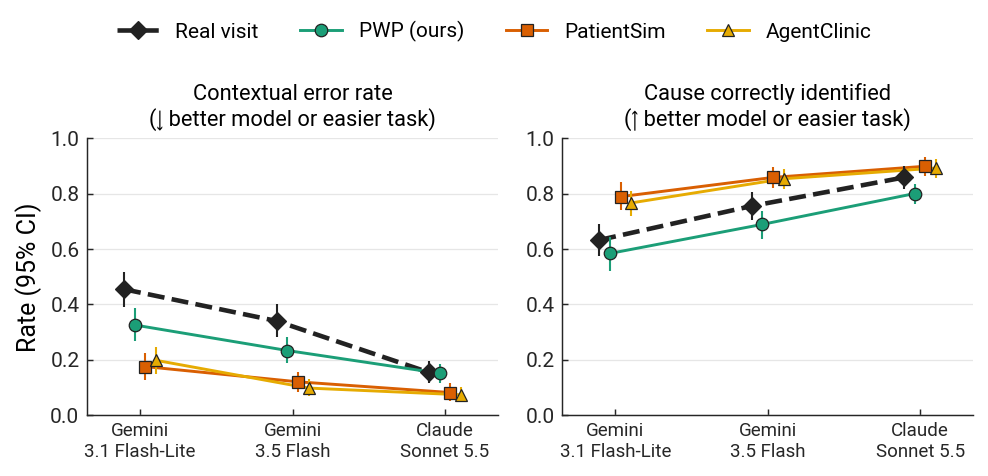

In [7]:
estimates = cc.estimates_frame(draws)
fig = cc.plot_benchmark(estimates)
save_to_figures(fig, "contextual_care_benchmark");

## Extreme personas

Exploratory run (`contextual_care_vha_persona`, 3 cases with 13 coded factors, three doctors × three seeds) replacing the default persona with a withholding patient (H = C = 3) and an emotional patient with a strong prior belief (E = O = 3). Persona minus default, pooled over doctors and seeds, with a paired bootstrap over factors.

In [8]:
persona = cc.load_results([Path("results/contextual_care_vha_persona/results.csv")])
personas = ["PWP withholding (H3 C3)", "PWP emotional (E3 O3)"]
print(
    persona[persona.has_factor]
    .groupby("arm")[["factor_elicited", "cause_correct", "contextual_error"]]
    .mean()
    .round(2)
    .loc[[f"{DOCTOR}:{p}" for p in ["PWP", *personas]]]
    .to_string()
)
print()
print(
    cc.persona_effect_table(persona, personas, "PWP", n_boot=5000, seed=0).to_string()
)

                                factor_elicited  cause_correct  contextual_error
arm                                                                             
strong:PWP                                 0.91           0.68              0.19
strong:PWP withholding (H3 C3)             0.49           0.36              0.47
strong:PWP emotional (E3 O3)               0.84           0.53              0.34

                                        cause_correct    contextual_error        factor_elicited
doctor persona                                                                                  
weak   PWP withholding (H3 C3)  -0.25 [-0.38, -0.12]*  0.21 [0.08, 0.36]*  -0.32 [-0.45, -0.19]*
       PWP emotional (E3 O3)      -0.15 [-0.32, 0.03]  0.15 [0.00, 0.29]*    -0.02 [-0.13, 0.09]
strong PWP withholding (H3 C3)  -0.32 [-0.47, -0.18]*  0.28 [0.16, 0.41]*  -0.42 [-0.55, -0.29]*
       PWP emotional (E3 O3)    -0.15 [-0.24, -0.07]*  0.15 [0.07, 0.24]*    -0.07 [-0.15, 0.03]


## Example: case Z221

The coded factor is a health belief: the patient feels medication should not "go in" the body. In the real visit it is mentioned only in passing, and all three doctor models miss it. Per run, whether the doctor's plan ignored the factor (`contextual_error`) and whether the patient voiced it:

In [9]:
z221 = df[(df.case_id == "Z221") & (df.flag_idx == 5)]
print(
    z221[z221.arm.isin(SIMULATOR_ARMS)]
    .pivot_table(
        index="arm",
        columns="model",
        values=["contextual_error", "factor_elicited"],
        aggfunc="sum",
    )
    .to_string()
)

                    contextual_error                                          factor_elicited                                       
model              claude-sonnet-5-5 gemini-3.1-flash-lite gemini-3.5-flash claude-sonnet-5-5 gemini-3.1-flash-lite gemini-3.5-flash
arm                                                                                                                                 
real_no_plan                     3.0                   3.0              3.0               3.0                   3.0              3.0
strong:AgentClinic               1.0                   1.0              0.0               3.0                   3.0              3.0
strong:PWP                       2.0                   3.0              3.0               3.0                   1.0              2.0
strong:PatientSim                0.0                   0.0              0.0               3.0                   3.0              3.0


In [10]:
run_dir = Path(
    "results/contextual_care_vha_ext/PatientsWithPersonality_H2_E1_X1_A2_C2_O1_LB/gemini-3.5-flash/strong/Z221"
)
for _, turn in pd.read_csv(run_dir / "turns_0.csv").iterrows():
    print(f"{turn.role.upper():>9}: {turn.content}")
print()
print(json.loads((run_dir / "assessment_0.json").read_text())["5"])

  PATIENT: Always need the bathroom. Even at night. Just... tired of it. It's nothing, really.
ASSISTANT: I hear how exhausting that must be. I noticed your blood sugar hasn't been checked in about a month and a half—what's been getting in the way of checking it lately?
  PATIENT: Well, just been busy. Forget sometimes. Numbers, they don't change much anyway. Just feels like a waste of time.
ASSISTANT: I also noticed that your medication refills have been a bit irregular lately, and your current one is overdue. What has been making it hard to get your refills on time?
  PATIENT: Just... slips my mind. Pharmacy's a hassle. Honestly, don't think it's doing much, so, uh, haven't rushed.
ASSISTANT: I see in your chart that we previously discussed a recommended treatment plan that you decided not to go ahead with. Could you tell me a bit more about what went into that decision?
  PATIENT: Don't like the sound of it. Doesn't feel right. Just, uh, seems unnecessary for what it is. I'll be fin